<a href="https://colab.research.google.com/github/gabrielemartorano04/GabrieleMartorano_MachineLearning_25-26/blob/main/Predicting_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Predicting Customer Churn Using Machine Learning***


Group Number: 6

Names: Alexander Younis, Yusuf Mohamed, Gabriele Martorano, Adyan Iqbal

---



Install dependencies and import libraries and raw dataset

In [1]:
#Installing dependencies
!pip install catboost shap --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import *

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from catboost import CatBoostClassifier

import shap

# Load the raw CSV into a DataFrame
URL = 'https://drive.google.com/file/d/19niO1lKnOiEDKFJCrAxdDpxWD3cz7208/view?usp=sharing'
path = 'https://drive.google.com/uc?export=download&id='+URL.split('/')[-2]
df = pd.read_csv(path)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.0 MB/s eta 0:00:00


### **Explorative Data Analysis**

---



In [2]:
print("\n- Number of rows and columns:", df.shape) # Prints number of rows and columns...should output (7043, 21)

pd.set_option('display.max_columns', None) # Ensures no hidden (...) columns
pd.set_option('display.max_rows', None) # Ensures no hidden (...) rows
print("\n\n- Preview the first 5 rows:\n\n", df.head()) # Preview the first 5 rows to visualize the data

print("\n\n- Data types for each column:\n\n", df.dtypes) # Data types for each column


- Number of rows and columns: (7043, 21)


- Preview the first 5 rows:

    customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV

In [3]:
df.shape
df.isnull().sum()
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [4]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

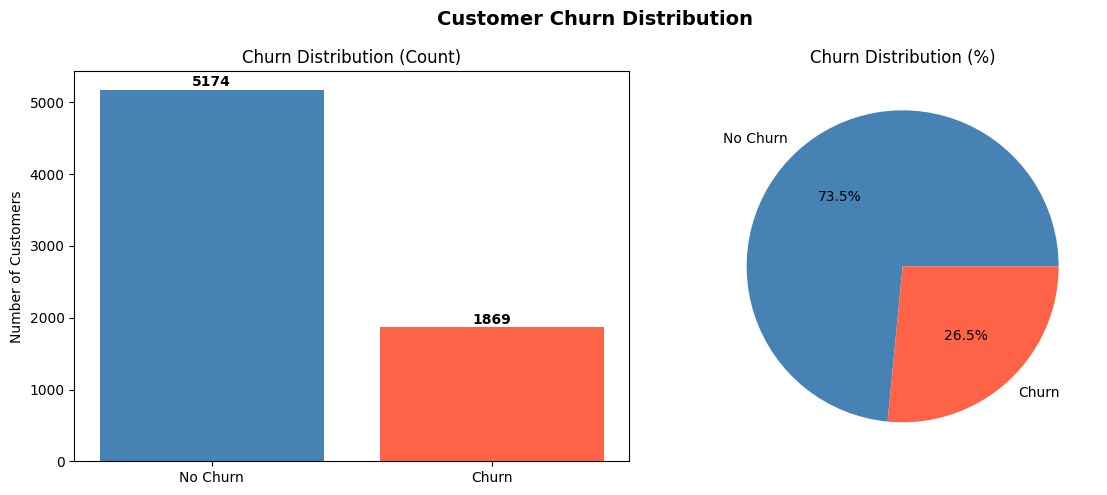

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Count plot
churn_counts = df['Churn'].value_counts()
axes[0].bar(['No Churn', 'Churn'], churn_counts, color=['steelblue', 'tomato'])
axes[0].set_title('Churn Distribution (Count)')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts):
    axes[0].text(i, v + 50, f'{v}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(churn_counts, labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'])
axes[1].set_title('Churn Distribution (%)')

plt.suptitle('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot1_churn_distribution.png', dpi=150)
plt.show()

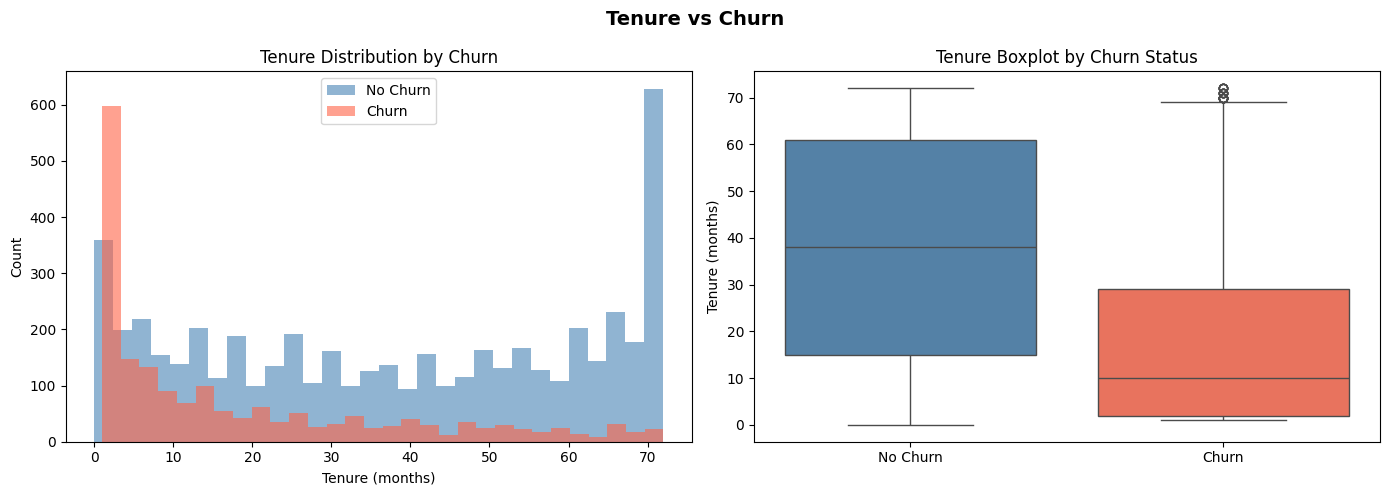

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram overlay
for label, color in zip([0, 1], ['steelblue', 'tomato']):
    axes[0].hist(df[df['Churn'] == label]['tenure'],
                 bins=30, alpha=0.6, label=['No Churn', 'Churn'][label], color=color)
axes[0].set_title('Tenure Distribution by Churn')
axes[0].set_xlabel('Tenure (months)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Box plot
df['Churn_Label'] = df['Churn'].map({0: 'No Churn', 1: 'Churn'})
sns.boxplot(
    data=df,
    x='Churn_Label',
    y='tenure',
    hue='Churn_Label',
    palette={'No Churn': 'steelblue', 'Churn': 'tomato'},
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Tenure Boxplot by Churn Status')
axes[1].set_xlabel('')
axes[1].set_ylabel('Tenure (months)')

plt.suptitle('Tenure vs Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot2_tenure_vs_churn.png', dpi=150)
plt.show()

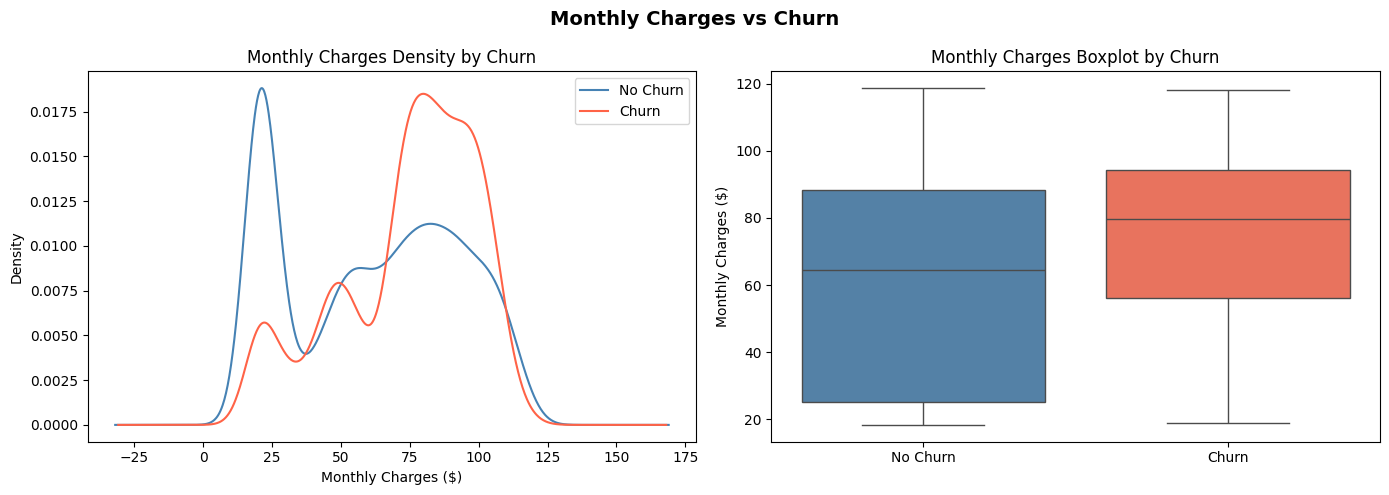

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE (density) plot
for label, color in zip([0, 1], ['steelblue', 'tomato']):
    df[df['Churn'] == label]['MonthlyCharges'].plot(
        kind='density', ax=axes[0], label=['No Churn', 'Churn'][label], color=color)
axes[0].set_title('Monthly Charges Density by Churn')
axes[0].set_xlabel('Monthly Charges ($)')
axes[0].legend()

# Box plot
sns.boxplot(data=df, x='Churn_Label', y='MonthlyCharges',
            hue='Churn_Label', legend=False,
            palette={'No Churn': 'steelblue', 'Churn': 'tomato'}, ax=axes[1])
axes[1].set_title('Monthly Charges Boxplot by Churn')
axes[1].set_xlabel('')
axes[1].set_ylabel('Monthly Charges ($)')

plt.suptitle('Monthly Charges vs Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot3_monthly_charges_vs_churn.png', dpi=150)
plt.show()

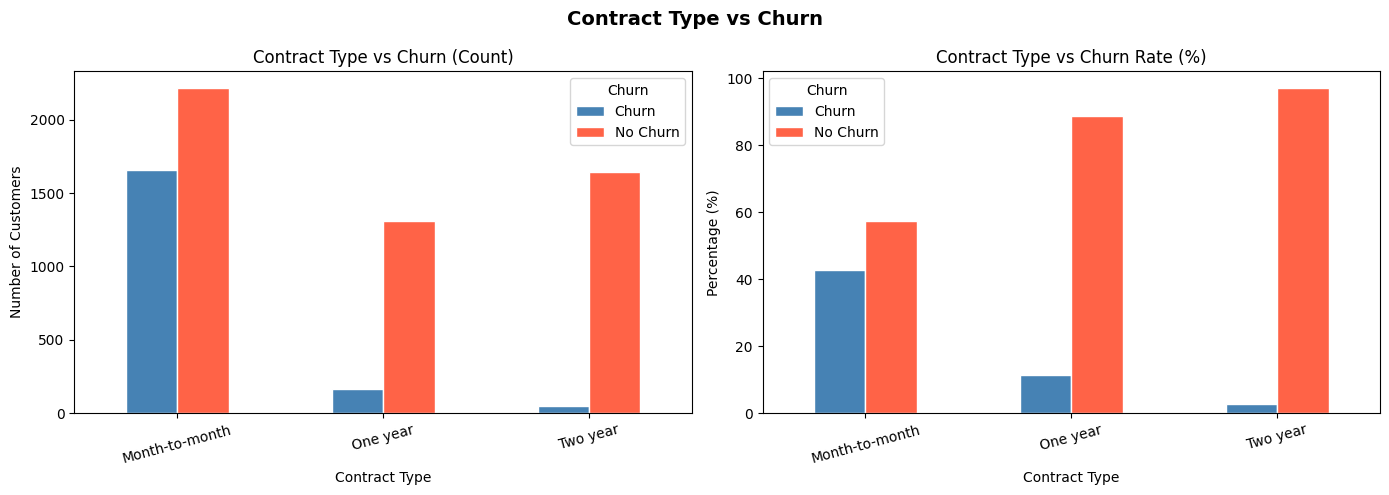

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stacked bar — absolute counts
contract_churn = df.groupby(['Contract', 'Churn_Label']).size().unstack()
contract_churn.plot(kind='bar', ax=axes[0], color=['steelblue', 'tomato'],
                    edgecolor='white')
axes[0].set_title('Contract Type vs Churn (Count)')
axes[0].set_xlabel('Contract Type')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Churn')

# Normalized bar — churn rate %
contract_churn_pct = contract_churn.div(contract_churn.sum(axis=1), axis=0) * 100
contract_churn_pct.plot(kind='bar', ax=axes[1], color=['steelblue', 'tomato'],
                         edgecolor='white')
axes[1].set_title('Contract Type vs Churn Rate (%)')
axes[1].set_xlabel('Contract Type')
axes[1].set_ylabel('Percentage (%)')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='Churn')

plt.suptitle('Contract Type vs Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot4_contract_vs_churn.png', dpi=150)
plt.show()

### **Data Cleaning & Preprocessing**

---



TotalCharges Empty String - New customers (tenure=0) have no billing yet — treated as null, not zero. Must be imputed to avoid breaking the model

In [9]:
blank_totalcharges = df["TotalCharges"].astype(str).str.strip().eq("").sum() # This line takes TotalCharges, converts everything to a string, removes spaces using .strip(), checks if the value is empty then counts the amount of True's
print("\n- Number of \"TotalCharges\" values that exist:", blank_totalcharges) # Prints how many blank "TotalCharges" values exist.

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce') # Turns TotalCharges to numbers and blanks become NaN value.
df["TotalCharges"] = df["TotalCharges"].fillna(0) # Replaces the NaN values with 0 as new customers with 0 tenure (number of months a customer has stayed with a telco)
print("\n- The number of missing values remaining is:", df["TotalCharges"].isna().sum()) # .isna() checks if its numm and then .sum() creates a count of the missing values remaining
print("\n- Preview the first 5 rows:\n\n", df[["tenure", "MonthlyCharges", "TotalCharges"]].head()) # Preview the first 5 rows to verify the corrected data (without "TotalCharges" having blank or null spaces)


- Number of "TotalCharges" values that exist: 11

- The number of missing values remaining is: 0

- Preview the first 5 rows:

    tenure  MonthlyCharges  TotalCharges
0       1           29.85         29.85
1      34           56.95       1889.50
2       2           53.85        108.15
3      45           42.30       1840.75
4       2           70.70        151.65


Save clean copy of dataset before encoding

In [10]:
clean_df = df.copy() # Creates a clean copy of the dataset to save prior to encoding

Preparing the dataset for machine learning

In [11]:
clean_df = clean_df.drop(columns=["customerID"]) # Removes customerID as its only an identifier and has no meaningful correlation thus shouldnt be used as a predictive feature

print("- The first 5 rows to validate if Churn is 1s and 0s\n\n", clean_df[["Churn"]].head()) # Previews the first 5 rows to validate it became 1s and 0s
print("\n- Shape WITHOUT customerID: ", clean_df.shape) # Prints the shape WITHOUT customerID to verify correct change

- The first 5 rows to validate if Churn is 1s and 0s

    Churn
0      0
1      0
2      1
3      0
4      1

- Shape WITHOUT customerID:  (7043, 21)


Separate features and encode categorical variables

In [12]:
X = clean_df.drop(columns=["Churn", "Churn_Label"], errors="ignore") # Stores all the predictor (Churn) variables in X to be used as model inputs
y = clean_df["Churn"] # Stores the target column in "y" so it can be predicted by the models

cat_columns = X.select_dtypes(include="object").columns.tolist() # Selects all the text based columns and creates a list to be encoded
print("- The remaining feature object columns to be encoded:\n\n", cat_columns) # Prints all the other columns that will be one-hot encoded

X = pd.get_dummies(X, columns=cat_columns, drop_first=True) # Converts the text columns (cat_columns) into numeric columns with one-hot encoding (turning it into binary columns "1 or 0")
print("\n- Shape AFTER encoding: ", X.shape) # Prints the shape after encoding (10 column increase than last model_df shape)
print("\n- Encoded feature table to confirm dummy variables:\n", X.head()) # Prints the encoded feature table to confirm dummy variables are created.

- The remaining feature object columns to be encoded:

 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

- Shape AFTER encoding:  (7043, 30)

- Encoded feature table to confirm dummy variables:
    SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False

80/20 train-test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42) # Splits encoded data into 80% training and 20% testing (test_size=0.2) while preserving the churn ratio. stratify=y keeps churn ratio (or split of data) the same in both sets. random_state=42 ensures the same randomness per every run.

print("- Training Feature Set Shape:", X_train.shape) # Prints the shape of the training feature set
print("\n- Test Feature Set Shape:", X_test.shape)# Prints the shape of the test feature set
print("\n- Churn percentage of training set:\n", y_train.value_counts(normalize=True)) # Shows churn percentage of training set to verify the stratified split worked
print("\n- Churn percentage of test set:\n", y_test.value_counts(normalize=True)) # Shows churn percentage of test set to verify the stratified split worked and equal similar

- Training Feature Set Shape: (5634, 30)

- Test Feature Set Shape: (1409, 30)

- Churn percentage of training set:
 Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

- Churn percentage of test set:
 Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


Final Checks

In [14]:
print("\n- Missing Values in encoded set:", X.isna().sum().sum()) # Counts the total num of missing values left in encoded data set
print("\n- Missing Values in output feature column:", y.isna().sum()) # confirms the output column has no missing values
print("\n- First 5 input feature training rows:\n", X_train.head()) # Previews the first 5 input feature training rows to verify the model is correct
print("\n- First 5 output feature training rows:\n", y_train.head()) # Previews the first 5 output feature training rows to verify the model is correct


- Missing Values in encoded set: 0

- Missing Values in output feature column: 0

- First 5 input feature training rows:
       SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
3738              0      35           49.20       1701.65         True   
3151              0      15           75.10       1151.55         True   
4860              0      13           40.55        590.35         True   
3867              0      26           73.50       1905.70        False   
3810              0       1           44.55         44.55         True   

      Partner_Yes  Dependents_Yes  PhoneService_Yes  \
3738        False           False             False   
3151         True            True              True   
4860         True            True             False   
3867         True           False              True   
3810         True            True              True   

      MultipleLines_No phone service  MultipleLines_Yes  \
3738                            True      

### **Baseline Models**

---



Scale clean dataset

In [15]:
# Initialize the StandardScaler to normalize feature distribution
scaler = StandardScaler()

# Fit the scaler on the training and transform it
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# Transform the test data using the same scaler to prevent data leakage
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

Training Dataset

In [16]:
# Define a helper function to quicly calculate and return all evaluation metrics
def evaluate_model(model, data_test_scaled, y_test, model_name):

  # Generate binary prediction (0 or 1)
  y_pred = model.predict(data_test_scaled)

  # Extract probability scores for the positive class (Churn) to calculate ROC-AUC
  y_prob = model.predict_proba(data_test_scaled)[:,1]

  # Return a dictionary containing the model's name and its performance metrics
  # zero_divison=0 prevents the warning if the model predicts churns
  return{
      "Model": model_name,
      "Accuracy": accuracy_score(y_test, y_pred),
      "Precision": precision_score(y_test, y_pred, zero_division=0),
      "Recall": recall_score(y_test, y_pred),
      "F1-Score": f1_score(y_test, y_pred, zero_division=0),
      "ROC-AUC": roc_auc_score(y_test, y_prob)
  }

Logistic Regression

In [17]:
# Initialize Logistic Regression. 'class_weight=balanced' automatically adjust weights inversely proportional to class frequencies
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# Train the model on the scaled training data
log_reg.fit(X_train_scaled, y_train)

# Evaluate the model and store the results
res_log = evaluate_model(log_reg, X_test_scaled, y_test, "Logistic Regression")

Decision tree

In [18]:
# Initialize Decision Tree with balanced class weights to handle the 73/26 churn imbalance
tree = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# Train the model
tree.fit(X_train_scaled, y_train)

# Evaluate the model and store the results
res_tree = evaluate_model(tree, X_test_scaled, y_test, "Decision Tree")

K-Nearest Neighbors (KNN)

In [19]:
# Initialize KNN with 5 neighbors
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

# Evaluate the model and store the results
res_knn = evaluate_model(knn, X_test_scaled, y_test, "KNN")

Result Metrics Table

In [20]:
# Combine all the results into a single pandas DataFrame and round to 4 decimal places for readability
result_df = pd.DataFrame([res_log, res_tree, res_knn]).round(4)

# Print a header and display the formatted table
print("METRICS TABLE")
display(result_df)

METRICS TABLE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7402,0.5069,0.7861,0.6164,0.8414
1,Decision Tree,0.7310,0.4931,0.4759,0.4844,0.6500
2,KNN,0.7473,0.5253,0.5000,0.5123,0.7716


Metrics Bar Chart

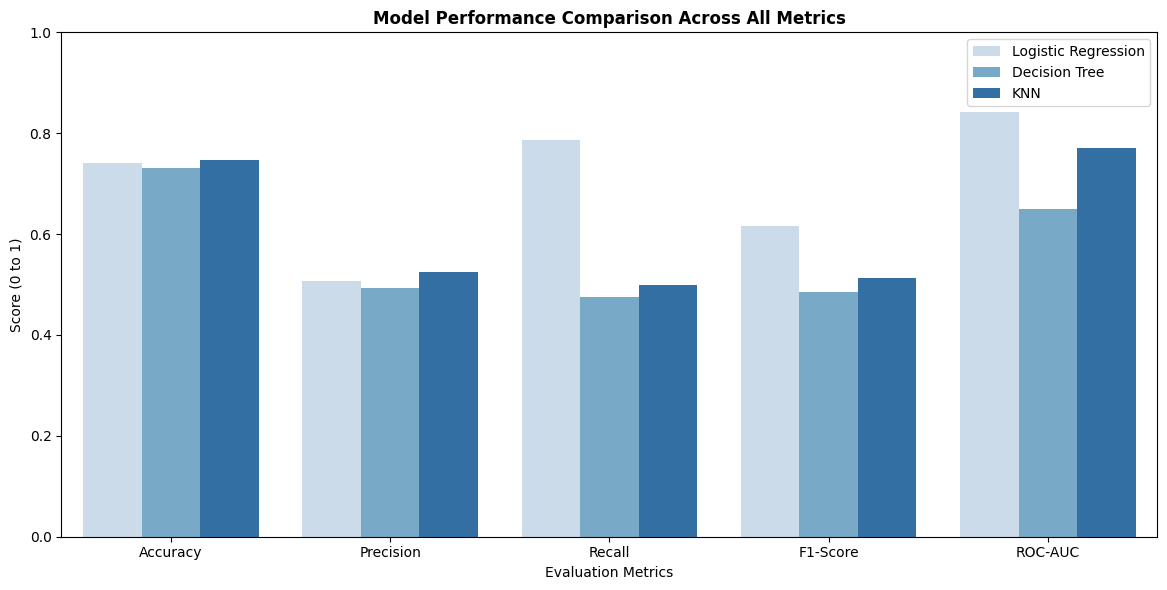

In [21]:
# Melt the result_df to a long format suitable for seaborn barplot
# This allows comparing all metrics side-by-side for each model
metrics_melted = result_df.melt(id_vars='Model', var_name='Metric', value_name='Value')

# Initialize the figure size
plt.figure(figsize=(12, 6))

# Create a grouped bar chart
sns.barplot(data=metrics_melted, x='Metric', y='Value', hue='Model', palette='Blues')

# Add titles and labels
plt.title('Model Performance Comparison Across All Metrics', fontweight='bold')
plt.ylabel('Score (0 to 1)')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1) # Ensure the scale is consistent (0 to 100%)
plt.legend(bbox_to_anchor=(0.82, 1), loc='upper left')
plt.tight_layout()
plt.show()

ROC Curve

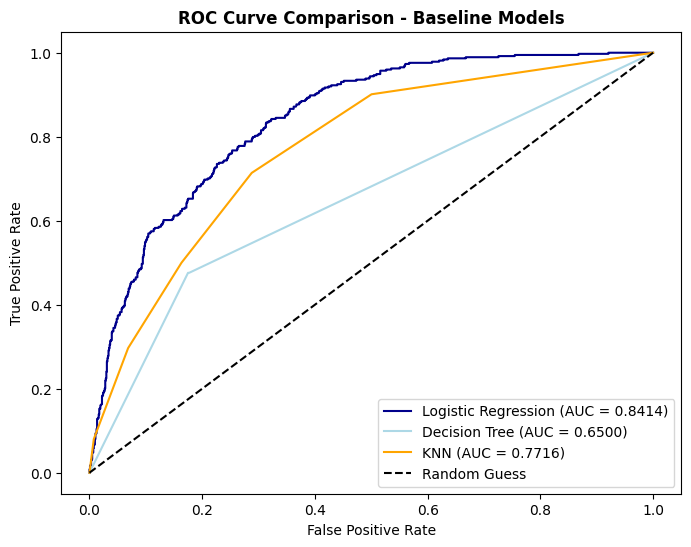

In [22]:
# Initialize a new matplotlib figure with a specific width (8) and height (6)
plt.figure(figsize=(8, 6))

# --- Logistic Regression ---
# Extract the predicted probabilities for the positive class (Churn = 1)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]
# Calculate the False Positive Rate (fpr) and True Positive Rate (tpr)
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
# Plot the ROC curve for Logistic Regression and include its AUC score in the legend
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {result_df.loc[0, "ROC-AUC"]:.4f})', color='darkblue')

# --- Decision Tree ---
# Extract the predicted probabilities for the positive class
y_prob_tree = tree.predict_proba(X_test_scaled)[:, 1]
# Calculate the False Positive Rate (fpr) and True Positive Rate (tpr)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
# Plot the ROC curve for Decision Tree and include its AUC score in the legend
plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {result_df.loc[1, "ROC-AUC"]:.4f})', color='lightblue')

# --- K-Nearest Neighbors (KNN) ---
# Extract the predicted probabilities for the positive class
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]
# Calculate the False Positive Rate (fpr) and True Positive Rate (tpr)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
# Plot the ROC curve for KNN and include its AUC score in the legend
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {result_df.loc[2, "ROC-AUC"]:.4f})', color='orange')

# Plot a dashed diagonal line representing a random guess model (50% accuracy)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Add a descriptive title to the plot and make the font bold
plt.title('ROC Curve Comparison - Baseline Models', fontweight='bold')

# Set the label for the horizontal x-axis (False Positive Rate)
plt.xlabel('False Positive Rate')

# Set the label for the vertical y-axis (True Positive Rate)
plt.ylabel('True Positive Rate')

# Display the legend in the lower right corner to avoid overlapping with the curves
plt.legend(loc='lower right')

# Render and display the final visualization on the screen
plt.show()

Precision-Recall Curve

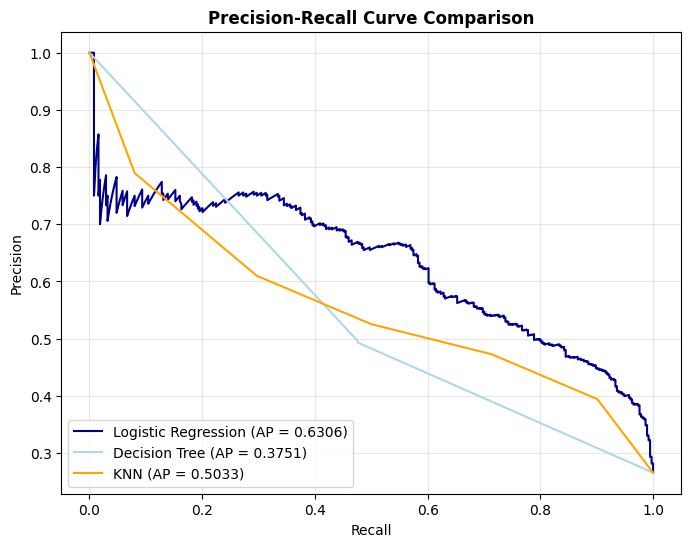

In [23]:
# Initialize the figure
plt.figure(figsize=(8, 6))

# Define models and their colors for the plot
models_list = [(log_reg, 'Logistic Regression', 'darkblue'),
               (tree, 'Decision Tree', 'lightblue'),
               (knn, 'KNN', 'orange')]

# Loop through models to calculate and plot the Precision-Recall curve
for model, name, color in models_list:
    # Get probability scores for the positive class (Churn)
    y_probs = model.predict_proba(X_test_scaled)[:, 1]
    # Calculate precision and recall values
    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    # Calculate the Average Precision (AP) score
    ap_score = average_precision_score(y_test, y_probs)
    # Plot the curve
    plt.plot(recall, precision, label=f'{name} (AP = {ap_score:.4f})', color=color)

# Set plot titles and labels in English for the IEEE report
plt.title('Precision-Recall Curve Comparison', fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.show()

Confusion Matrix Graphs

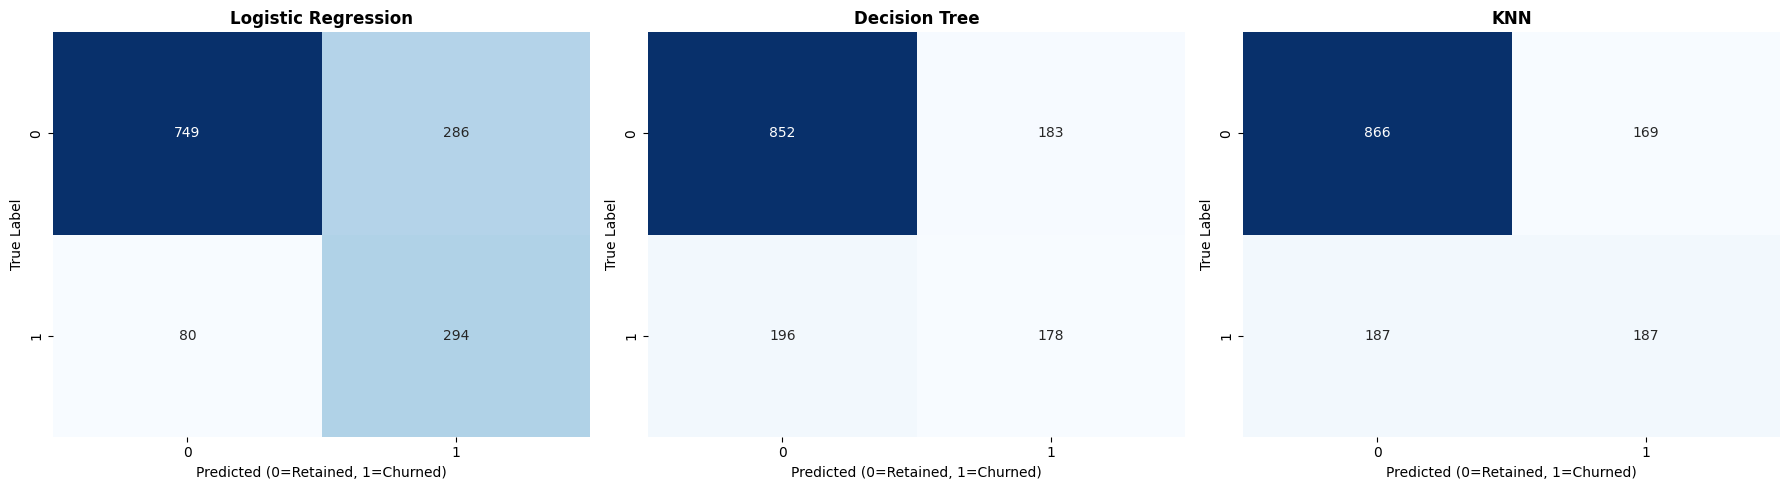

In [24]:
# Create lists containing out trained models and their respective names for the plot
models = [log_reg, tree, knn]
model_names = ["Logistic Regression", "Decision Tree", "KNN"]

# Set up a 1x3 grid for the subplots with a specific figure size
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loop through each model to generate and plot its confusion matrix
for i, model in enumerate(models):

  # Predict the target values for the test set
  y_pred = model.predict(X_test_scaled)

  # Calculate the confusion matrix (True Positives, False Positives, etc.)
  cm = confusion_matrix(y_test, y_pred)

  # Plot the matrix as a heatmap using seaborn
  # annot=True displays the numbers, fmt='d' formats them as integers, cmap='Blues' sets the color theme
  sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)

  # Sets the title and labels for each subplot
  axes[i].set_title(f'{model_names[i]}', fontweight='bold')
  axes[i].set_xlabel('Predicted (0=Retained, 1=Churned)')
  axes[i].set_ylabel('True Label')

# Adjust the layout to prevent overlapping elements
plt.tight_layout()

# Display the final visualization
plt.show()


Feature Importance

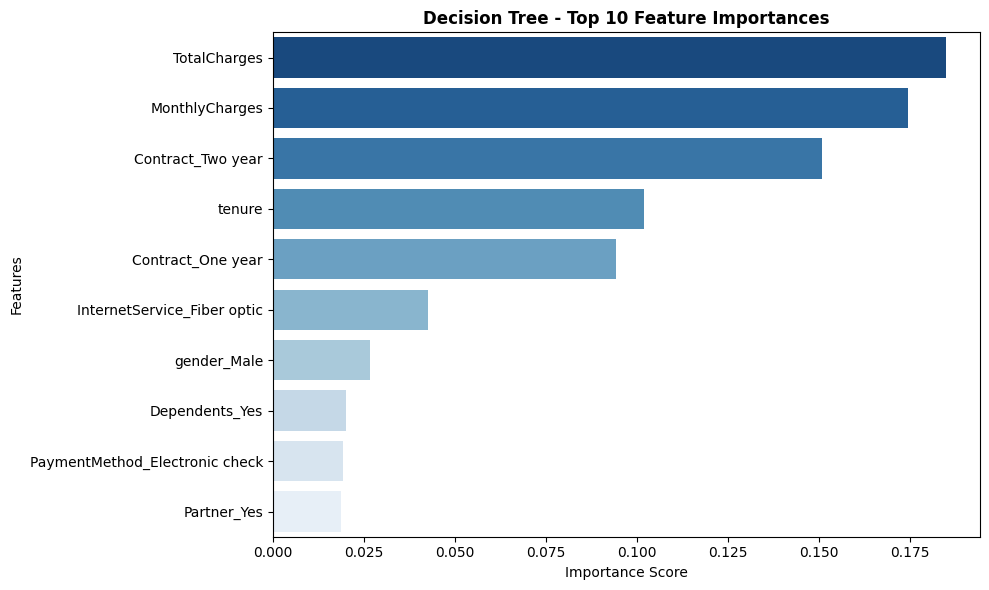

In [25]:
# Extract the feature importance scores from the trained Decision Tree and map them to their respective column names
feature_importances = pd.Series(tree.feature_importances_, index=X_train.columns)

# Isolate the top 10 features that have the highest importance scores
top_features = feature_importances.nlargest(10)

# Initialize a new matplotlib figure with a specific width (10) and height (6)
plt.figure(figsize=(10, 6))

# Generate a horizontal bar plot; assign 'y' to 'hue' and set 'legend=False' to avoid the seaborn deprecation warning
sns.barplot(x=top_features.values, y=top_features.index, hue=top_features.index, legend=False, palette='Blues_r')

# Add a descriptive title to the top of the plot and make the font bold
plt.title('Decision Tree - Top 10 Feature Importances', fontweight='bold')

# Set the label for the horizontal x-axis
plt.xlabel('Importance Score')

# Set the label for the vertical y-axis
plt.ylabel('Features')

# Adjust the layout automatically to ensure no labels or titles are cut off
plt.tight_layout()

# Render and display the final visualization on the screen
plt.show()

### **Advanced models**

---



In [26]:
#Cross validation strategy shared across all 3 models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


Random Forest

In [27]:

#Hyperparameter search space

rf_params = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'max_features':      ['sqrt', 'log2'],
    'class_weight':      ['balanced', None]
}

#RandomizedSearchCV sampling 30 random combintions instead of all
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=30, scoring='roc_auc',
    cv=cv, random_state=42, n_jobs=-1
)

# Tree models unscaled data - x_train not x_train_scaled

rf_search.fit(X_train, y_train)

print("Best RF Parameters:", rf_search.best_params_)
print("Best CV ROC-AUC:   ", round(rf_search.best_score_, 4))

# Evaluate on test set using shared evaluate_model function

rf_best = rf_search.best_estimator_
res_rf = evaluate_model(rf_best, X_test, y_test, "Random Forest")



Best RF Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10, 'class_weight': 'balanced'}
Best CV ROC-AUC:    0.8462


CatBoost

In [29]:
# scale_pos_weight handles class imbalance — ratio of non-churners to churners
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos = round(neg / pos, 2)
print("scale_pos_weight:", scale_pos)

cb_params = {
    'iterations':    [200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'depth':         [4, 6, 8, 10],
    'l2_leaf_reg':   [1, 3, 5, 10],
    'subsample':     [0.7, 0.8, 1.0]
}

cb_search = RandomizedSearchCV(
    CatBoostClassifier(scale_pos_weight=float(scale_pos), random_seed=42, verbose=0),
    param_distributions=cb_params,
    n_iter=20, scoring='roc_auc',
    cv=cv, random_state=42, n_jobs=-1
)

cb_search.fit(X_train, y_train)

print("Best CatBoost Parameters:", cb_search.best_params_)
print("Best CV ROC-AUC:         ", round(cb_search.best_score_, 4))

cb_best = cb_search.best_estimator_
res_cb = evaluate_model(cb_best, X_test, y_test, "CatBoost")

scale_pos_weight: 2.77
Best CatBoost Parameters: {'subsample': 1.0, 'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 200, 'depth': 4}
Best CV ROC-AUC:          0.8497


MLP Neural Network

In [30]:
mlp_params = {
    'hidden_layer_sizes': [(64,), (128,), (64, 32), (128, 64), (128, 64, 32)],
    'activation':         ['relu', 'tanh'],
    'alpha':              [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01],
    'max_iter':           [300, 500],
    'early_stopping':     [True],
    'validation_fraction':[0.1]
}

mlp_search = RandomizedSearchCV(
    MLPClassifier(random_state=42),
    param_distributions=mlp_params,
    n_iter=20, scoring='roc_auc',
    cv=cv, random_state=42, n_jobs=-1
)

# MLP uses scaled data — same as baseline models
mlp_search.fit(X_train_scaled, y_train)

print("Best MLP Parameters:", mlp_search.best_params_)
print("Best CV ROC-AUC:    ", round(mlp_search.best_score_, 4))

mlp_best = mlp_search.best_estimator_
res_mlp = evaluate_model(mlp_best, X_test_scaled, y_test, "MLP")

Best MLP Parameters: {'validation_fraction': 0.1, 'max_iter': 300, 'learning_rate_init': 0.001, 'hidden_layer_sizes': (64,), 'early_stopping': True, 'alpha': 0.01, 'activation': 'relu'}
Best CV ROC-AUC:     0.8421


ROC Curves

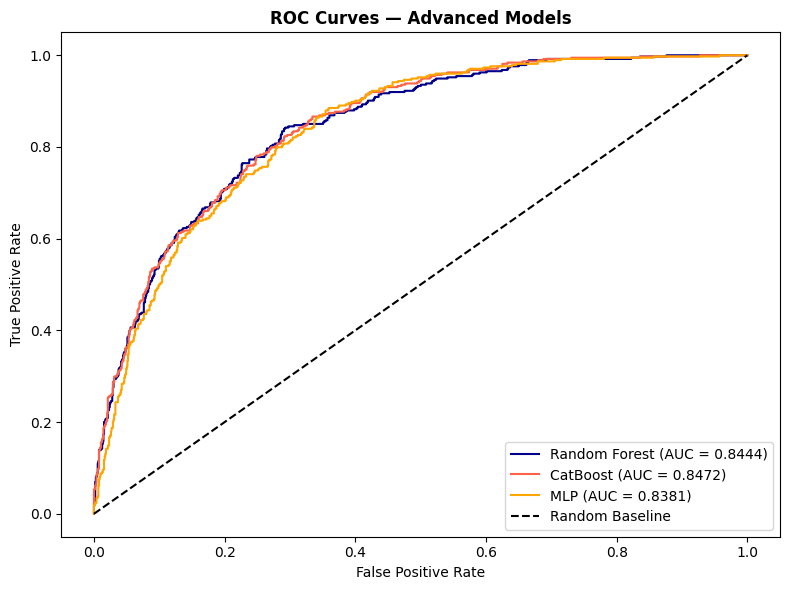

In [31]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_best.predict_proba(X_test)[:, 1])
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {res_rf["ROC-AUC"]:.4f})', color='darkblue')

# CatBoost
fpr_cb, tpr_cb, _ = roc_curve(y_test, cb_best.predict_proba(X_test)[:, 1])
plt.plot(fpr_cb, tpr_cb, label=f'CatBoost (AUC = {res_cb["ROC-AUC"]:.4f})', color='tomato')

# MLP
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, mlp_best.predict_proba(X_test_scaled)[:, 1])
plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {res_mlp["ROC-AUC"]:.4f})', color='orange')

# Baseline reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')

plt.title('ROC Curves — Advanced Models', fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.tight_layout()
plt.show()

Feature Importance - Random Forest

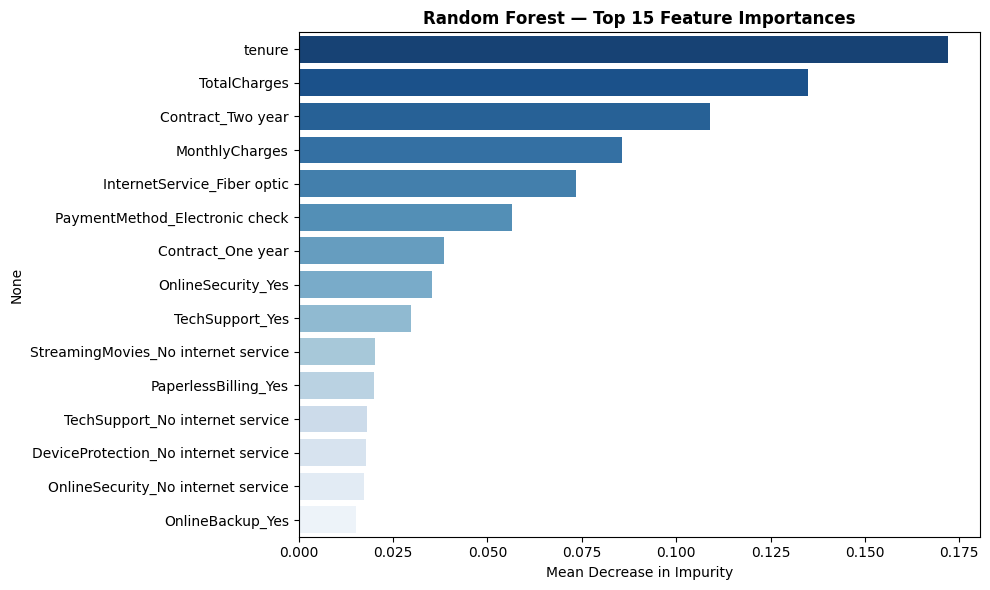

In [32]:
feature_importances = pd.Series(
    rf_best.feature_importances_, index=X_train.columns
)
top_features = feature_importances.nlargest(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_features.values,
    y=top_features.index,
    hue=top_features.index,
    palette='Blues_r',
    legend=False
)
plt.title('Random Forest — Top 15 Feature Importances', fontweight='bold')
plt.xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.show()

Shap Values - Catboost

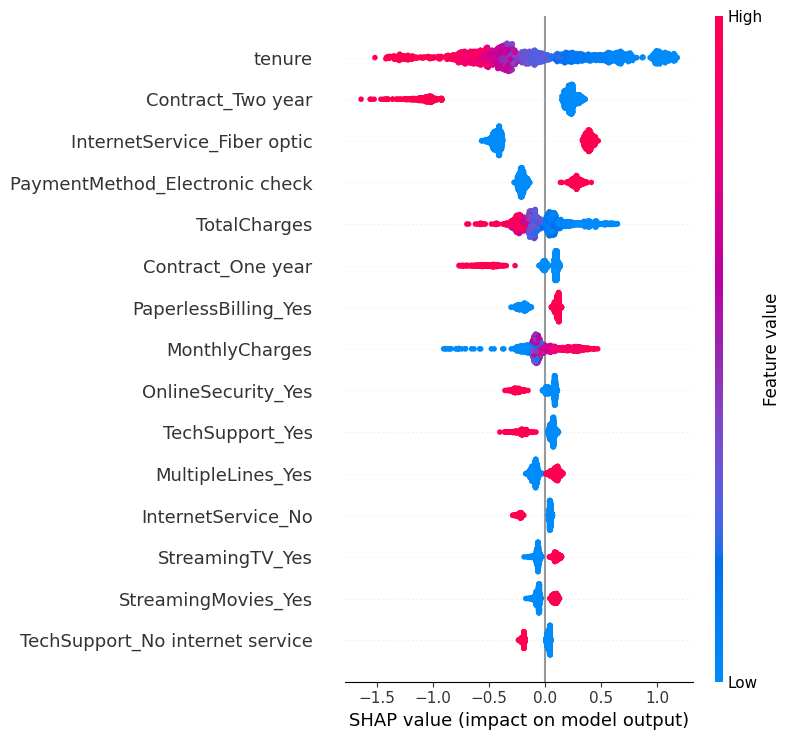

In [33]:
shap.initjs()

# TreeExplainer is optimized for tree based models like CatBoost
explainer   = shap.TreeExplainer(cb_best)
shap_values = explainer.shap_values(X_test)

# Summary plot shows direction and the magnitude per feature
shap.summary_plot(shap_values, X_test, plot_type='dot', max_display=15)

Comparing baseline results with my advanced results

In [34]:
all_results = pd.DataFrame([
    res_log, res_tree, res_knn,   # baseline
    res_rf, res_cb, res_mlp       # advanced
]).round(4)

print("FULL MODEL COMPARISON TABLE")
display(all_results)

FULL MODEL COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7402,0.5069,0.7861,0.6164,0.8414
1,Decision Tree,0.7310,0.4931,0.4759,0.4844,0.6500
2,KNN,0.7473,0.5253,0.5000,0.5123,0.7716
3,Random Forest,0.7637,0.5385,0.7674,0.6329,0.8444
4,CatBoost,0.7402,0.5067,0.8075,0.6227,0.8472
5,MLP,0.7956,0.6387,0.5294,0.5789,0.8381
